In [2]:
# alternative in case of bimodality: only include cells with same label

In [4]:
import jax
import jax.numpy as jnp
from ott.geometry import pointcloud
# from ott.solvers.linear import sinkhorn
from ott.tools import sinkhorn_divergence as sdiv
import time
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import pairwise_distances
from tqdm import tqdm

In [2]:
epsilon = 1 # 100 --> approaches all-to-all pairwise distances. The smaller, the more accurate, the slower

In [5]:
results_ot = dict()
results_pw_dist = dict()
for n in [1000]:
    results_ot[n] = list()
    results_pw_dist[n] = list()
    for i in tqdm(range(0,2)):
        rngs = jax.random.split(jax.random.PRNGKey(i), 2)
        d, n_x, n_y = 2, n, n
        x1 = jax.random.normal(rngs[0], (n_x, d))
        x2 = jax.random.normal(rngs[0],(n_x, d)) + 4
        y1 = jax.random.normal(rngs[1], (n_y, d)) + 1
        y2 = jax.random.normal(rngs[1], (n_y, d)) + 5
        x = jnp.concatenate((x1,x2),axis=0)
        y = jnp.concatenate((y1,y2),axis=0)
        # geom = pointcloud.PointCloud(x, y, epsilon=epsilon)
        # solve_fn = jax.jit(sinkhorn.solve)
        # # st = time.time()
        # ot_2 = solve_fn(geom, a=None, b=None)
        # et = time.time()
        # print('Execution time:', et-st, 'seconds or', time.strftime("%H:%M:%S", time.gmtime(et - st)))
        # results_ot[n].append(ot_2.kl_reg_cost)
        output = sdiv.sinkhorn_divergence(
            pointcloud.PointCloud,
            x=x,
            y=y,
            epsilon=epsilon,
        )
        results_ot[n].append(output.divergence)
        # results_pw_dist[n].append(pairwise_distances(x,y).mean())

100%|██████████| 2/2 [00:34<00:00, 17.15s/it]


In [6]:
output.divergence

Array(2.1428463, dtype=float32)

In [7]:
x.shape

(2000, 2)

In [8]:
y.shape

(2000, 2)

In [11]:
type(np.array(x))

numpy.ndarray

In [12]:
output2 = sdiv.sinkhorn_divergence(
            pointcloud.PointCloud,
            x=np.array(x),
            y=np.array(y),
            epsilon=epsilon,
        )

In [14]:
output2.divergence

Array(2.1428463, dtype=float32)

In [22]:
jax.devices('cpu')[0]

CpuDevice(id=0)

In [ ]:
print("JAX devices:", jax.devices())
print("GPU device count:", jax.device_count("gpu"))

In [8]:
print("JAX version:", jax.__version__)

JAX version: 0.4.30


In [9]:
import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE']='false'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION']='.30'

In [11]:
jax.devices()

[cuda(id=0)]

In [18]:
jax.device_get(output.divergence)

array(1.8481842, dtype=float32)

In [15]:
output.divergence.device()

AttributeError: 'jaxlib.xla_extension.ArrayImpl' object has no attribute 'device'

In [16]:
results_ot = dict()
results_pw_dist = dict()
for n in [10,100]:
    results_ot[n] = list()
    results_pw_dist[n] = list()
    for i in tqdm(range(0,100)):
        rngs = jax.random.split(jax.random.PRNGKey(i), 2)
        d, n_x, n_y = 2, n, n
        x1 = jax.random.normal(rngs[0], (n_x, d))
        x2 = jax.random.normal(rngs[0],(n_x, d)) + 4
        y1 = jax.random.normal(rngs[1], (n_y, d)) + 1
        y2 = jax.random.normal(rngs[1], (n_y, d)) + 5
        x = jnp.concatenate((x1,x2),axis=0)
        y = jnp.concatenate((y1,y2),axis=0)
        # geom = pointcloud.PointCloud(x, y, epsilon=epsilon)
        # solve_fn = jax.jit(sinkhorn.solve)
        # # st = time.time()
        # ot_2 = solve_fn(geom, a=None, b=None)
        # et = time.time()
        # print('Execution time:', et-st, 'seconds or', time.strftime("%H:%M:%S", time.gmtime(et - st)))
        # results_ot[n].append(ot_2.kl_reg_cost)
        output = sdiv.sinkhorn_divergence(
            pointcloud.PointCloud,
            x=x,
            y=y,
            epsilon=epsilon,
        )
        results_ot[n].append(output.divergence)
        results_pw_dist[n].append(pairwise_distances(x,y).mean())

100%|██████████| 100/100 [03:02<00:00,  1.82s/it]


In [17]:
results_df_ot = pd.DataFrame({'x':np.array(100*[10] + 100*[100]), 'y':np.array(results_ot[10] + results_ot[100])})
# results_df_ot = pd.DataFrame({'x':np.array(100*[10] + 100*[100] + 100*[1000]), 'y':np.array(results_ot[10] + results_ot[100] + results_ot[1000])})
results_df_pw_dist = pd.DataFrame({'x':np.array(100*[10] + 100*[100]), 'y':np.array(results_pw_dist[10] + results_pw_dist[100])})

### BIMODAL

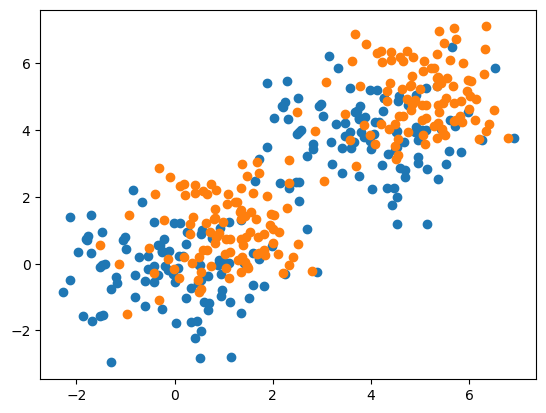

In [19]:
plt.scatter(x[:,0], x[:,1])
plt.scatter(y[:,0], y[:,1])
plt.show()

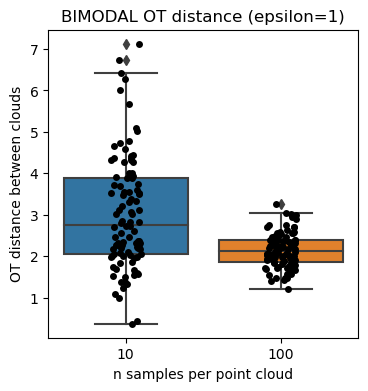

In [20]:
fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot()
sns.boxplot(results_df_ot, x='x',y='y',ax=ax)
sns.stripplot(results_df_ot, x='x',y='y',color='black',ax=ax)
ax.set_xlabel('n samples per point cloud')
ax.set_ylabel('OT distance between clouds')
ax.set_title(f'BIMODAL OT distance (epsilon={epsilon})')
plt.show()

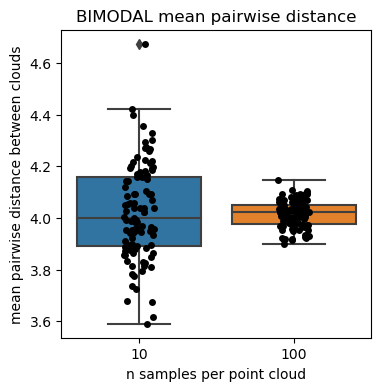

In [21]:
fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot()
sns.boxplot(results_df_pw_dist, x='x',y='y',ax=ax)
sns.stripplot(results_df_pw_dist, x='x',y='y',color='black',ax=ax)
ax.set_xlabel('n samples per point cloud')
ax.set_ylabel('mean pairwise distance between clouds') # update plot with correct ylabel
ax.set_title('BIMODAL mean pairwise distance')
plt.show()

### UNIMODAL

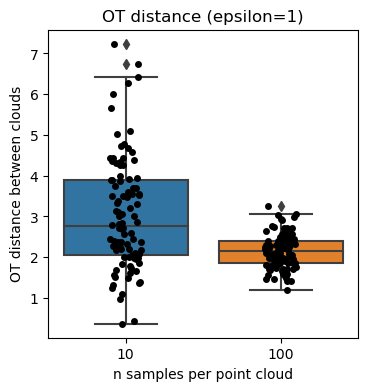

In [6]:
fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot()
sns.boxplot(results_df_ot, x='x',y='y',ax=ax)
sns.stripplot(results_df_ot, x='x',y='y',color='black',ax=ax)
ax.set_xlabel('n samples per point cloud')
ax.set_ylabel('OT distance between clouds')
ax.set_title(f'OT distance (epsilon={epsilon})')
plt.show()

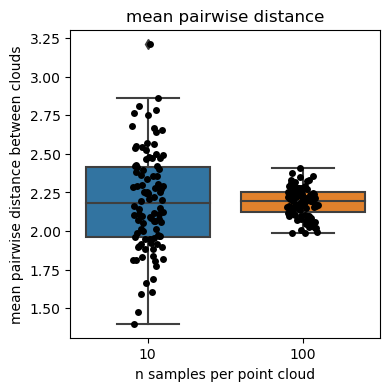

In [8]:
fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot()
sns.boxplot(results_df_pw_dist, x='x',y='y',ax=ax)
sns.stripplot(results_df_pw_dist, x='x',y='y',color='black',ax=ax)
ax.set_xlabel('n samples per point cloud')
ax.set_ylabel('mean pairwise distance between clouds') # update plot with correct ylabel
ax.set_title('mean pairwise distance')
plt.show()

In [9]:
np.sqrt(1**2 + 1**2)

1.4142135623730951

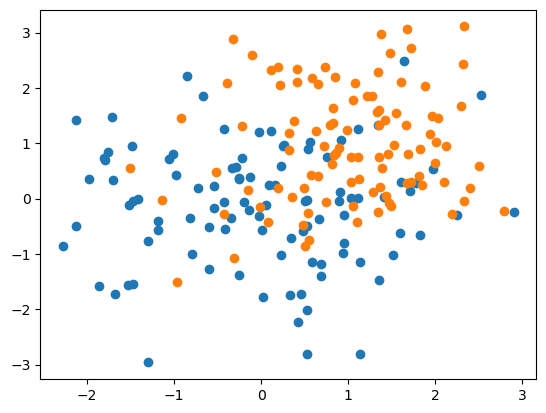

In [10]:
plt.scatter(x[:,0], x[:,1])
plt.scatter(y[:,0], y[:,1])